En los ítems $4.1$ a $4.3$ usamos los experimentos tamanos y desorden, y cada lista medida es una observación de la regresión. Para el ítem $4.4$ debera generar un nuevo set de listas de simulación variando el valor de $k$

In [16]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats

## Ejercicio 4.1

Complejidad de insertion sort. Con las mediciones para $n = 10, 20, 50, 100, 200, 500, 1000$, grafique $S_n$ en función de $n$ y muestre que la dependencia no es lineal.

In [17]:
ns = [10, 20, 50, 100, 200, 500, 1000]
sn_tamanos = {m: [] for m in ns}        # S_n 
qn_tamanos = {m: [] for m in ns}        # Q_n 

conteosJSON = open("conteos.jsonl", "r")

for linea in conteosJSON:
    datos = json.loads(linea)
    if datos["experimento"] == "tamanos":
        if datos["algoritmo"] == "insertion":
            sn_tamanos[datos["n"]].append(datos["swaps"])
        elif datos["algoritmo"] == "quick_primero":
            qn_tamanos[datos["n"]].append(datos["comparaciones"])

conteosJSON.close()

print("observaciones por n:", [len(sn_tamanos[m]) for m in ns])

observaciones por n: [200, 200, 200, 200, 200, 200, 200]


### a)

A partir de la fórmula de $E(S_n)$, ¿qué valores de $\beta_0$ y $\beta_1$ espera para $n$ grande en la regresión ln $S_n = \beta_0 + \beta_1 ln( n )+ \epsilon$? Ajústela y construya intervalos de confianza de nivel $0,95$ para $\beta_0$ y $\beta_1$. Contraste $H_0 : \beta_1 = 2$ usando todos los $n$ ($1400$ observaciones) y usando solo $n \geq 100$ ($800$ observaciones).

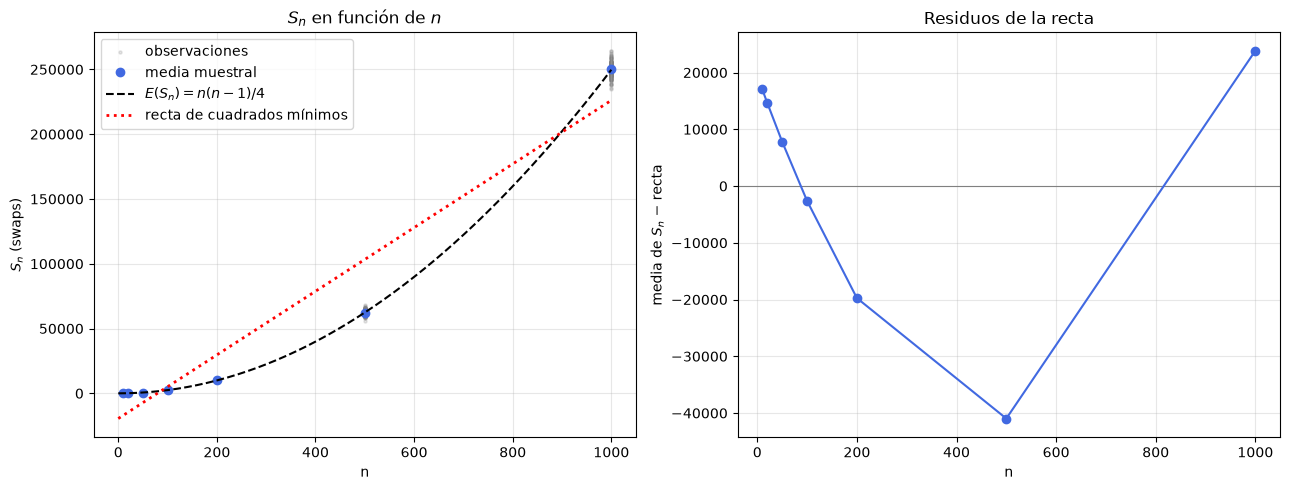

,N,β̂0,IC 95 % β0,β̂1,IC 95 % β1,t (H0: β1 = 2),p-valor
Ajuste,,,,,,,
todos los n,1400,-1.568721,"[-1.591, -1.546]",2.030569,"[2.0259, 2.0352]",12.87,6.89e-36
n ≥ 100,800,-1.433742,"[-1.455, -1.413]",2.006981,"[2.0034, 2.0106]",3.78,1.66e-04


In [18]:
# S_n en función de n
sn_medias = np.array([np.mean(sn_tamanos[m]) for m in ns])
x_obs = np.concatenate([np.full(len(sn_tamanos[m]), m) for m in ns])
y_obs = np.concatenate([sn_tamanos[m] for m in ns])

b, a = np.polyfit(x_obs, y_obs, 1)                  # recta S = a + b n sobre todas las observaciones
residuos_recta = sn_medias - (a + b * np.array(ns))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
ax1.scatter(x_obs, y_obs, s=5, alpha=0.2, color="gray", label="observaciones")
ax1.plot(ns, sn_medias, "o", color="royalblue", label="media muestral")
grilla = np.linspace(0, 1000, 300)
ax1.plot(grilla, grilla * (grilla - 1) / 4, "k--", label=r"$E(S_n)=n(n-1)/4$")
ax1.plot(grilla, a + b * grilla, "r:", lw=2, label="recta de cuadrados mínimos")
ax1.set_xlabel("n"); ax1.set_ylabel(r"$S_n$ (swaps)")
ax1.set_title(r"$S_n$ en función de $n$")
ax1.legend(); ax1.grid(alpha=0.3)

ax2.axhline(0, color="gray", lw=0.8)
ax2.plot(ns, residuos_recta, "o-", color="royalblue")
ax2.set_xlabel("n"); ax2.set_ylabel(r"media de $S_n$ − recta")
ax2.set_title("Residuos de la recta")
ax2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

#  regresión ln S_n = b0 + b1 ln n (4.1a)
def ols(x, y):
    """Cuadrados mínimos para y = b0 + b1 x. Errores clásicos y HC3 (robustos a varianza no constante)."""
    X = np.column_stack([np.ones_like(x), x])
    XtX_inv = np.linalg.inv(X.T @ X)
    beta = XtX_inv @ X.T @ y
    e = y - X @ beta
    gl = len(y) - 2
    se = np.sqrt(np.diag(e @ e / gl * XtX_inv))
    h = np.einsum("ij,jk,ik->i", X, XtX_inv, X)
    meat = X.T @ (X * (e**2 / (1 - h)**2)[:, None])
    se_hc3 = np.sqrt(np.diag(XtX_inv @ meat @ XtX_inv))
    return {"beta": beta, "se": se, "se_hc3": se_hc3, "resid": e, "gl": gl}

def datos_loglog(ms):
    x = np.concatenate([np.full(len(sn_tamanos[m]), np.log(m)) for m in ms])
    y = np.log(np.concatenate([sn_tamanos[m] for m in ms]))
    return x, y

x_todos, y_todos = datos_loglog(ns)
x_100, y_100 = datos_loglog([m for m in ns if m >= 100])
r_todos = ols(x_todos, y_todos)
r_100 = ols(x_100, y_100)

def fila_regresion(r, nombre):
    t975 = stats.t.ppf(0.975, r["gl"])
    (b0, b1), (se0, se1) = r["beta"], r["se"]
    t1 = (b1 - 2) / se1                                  # H0: β1 = 2
    p1 = 2 * stats.t.sf(abs(t1), r["gl"])
    return {"Ajuste": nombre, "N": r["gl"] + 2,
            "β̂0": b0, "IC 95 % β0": f"[{b0 - t975*se0:.3f}, {b0 + t975*se0:.3f}]",
            "β̂1": b1, "IC 95 % β1": f"[{b1 - t975*se1:.4f}, {b1 + t975*se1:.4f}]",
            "t (H0: β1 = 2)": round(t1, 2), "p-valor": f"{p1:.2e}"}

tabla_41a = pd.DataFrame([fila_regresion(r_todos, "todos los n"),
                          fila_regresion(r_100, "n ≥ 100")]).set_index("Ajuste")
display(tabla_41a)

### b)

Compare las estimaciones de los dos ajustes y explique la diferencia a partir de la fórmula exacta de E(S_n). Si con $n \geq 100$ el test también rechaza, ¿eso contradice que el exponente asintótico es $2$? ¿Qué tan grande es la diferencia entre $\hat{\beta_1}$ y $2$?

### c)

Calcule el desvío de ln $S_n$ para cada $n$. ¿Se cumple el supuesto de varianza constante?

### d) 

Aplique el test de Shapiro–Wilk a los residuos del ajuste con todos los $n$ y grafíquelos en un cuantil-cuantil contra la normal. Repita el test con los residuos de cada $n$ por separado. ¿Se cumple el supuesto de normalidad? ¿Qué explica la diferencia entre los dos resultados?

,2 ln n − ln 4,ln(1 − 1/n),E[ln S_n] (teórico),media muestral de ln S_n
n,,,,
10,3.2189,-0.1054,3.0827,3.0412
20,4.6052,-0.0513,4.5407,4.5441
50,6.4378,-0.0202,6.4128,6.4140
100,7.8240,-0.0101,7.8117,7.8082
200,9.2103,-0.0050,9.2042,9.2001
500,11.0429,-0.0020,11.0405,11.0403
1000,12.4292,-0.0010,12.4280,12.4289


,β̂1 (muestra),β1 teórico,β̂0 (muestra),β0 teórico
todos los n,2.0306,2.0253,-1.5687,-1.5382
n ≥ 100,2.0070,2.0047,-1.4337,-1.4190


,media de ln S_n,desvío de ln S_n,σ/μ de S_n (teórico)
n,,,
10,3.0412,0.2844,0.2485
20,4.5441,0.1598,0.1622
50,6.4140,0.0977,0.0976
100,7.8082,0.0690,0.0678
200,9.2001,0.0471,0.0476
500,11.0403,0.0309,0.0299
1000,12.4289,0.0211,0.0211


EE de β̂1, todos los n:  clásico = 0.00238   HC3 = 0.00309
EE de β̂1, n ≥ 100:      clásico = 0.00185   HC3 = 0.00201
Shapiro-Wilk, residuos de todos los n: W = 0.8235, p-valor = 1.09e-36


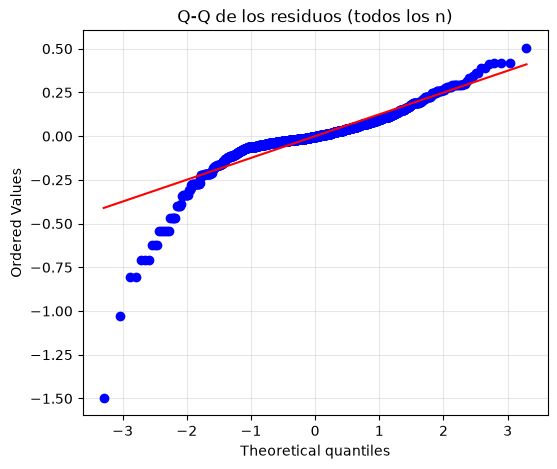

,W,p-valor,¿rechaza al 5 %?
n,,,
10,0.9346,0.0000,True
20,0.9895,0.1524,False
50,0.9940,0.5985,False
100,0.9899,0.1718,False
200,0.9914,0.2807,False
500,0.9963,0.9128,False
1000,0.9950,0.7485,False


In [19]:


# %% comparación con la fórmula exacta (4.1b)
def e_ln_S(m):
    """E[ln S_n] ≈ ln E(S_n) − Var(S_n) / (2 E(S_n)²)  (aproximación de segundo orden)."""
    mu = m * (m - 1) / 4
    var = m * (m - 1) * (2 * m + 5) / 72
    return np.log(mu) - var / (2 * mu**2)

tabla_41b_ln = pd.DataFrame({
    "2 ln n − ln 4": 2 * np.log(ns) - np.log(4),
    "ln(1 − 1/n)": np.log(1 - 1 / np.array(ns)),
    "E[ln S_n] (teórico)": [e_ln_S(m) for m in ns],
    "media muestral de ln S_n": [np.mean(np.log(sn_tamanos[m])) for m in ns],
}, index=pd.Index(ns, name="n"))
display(tabla_41b_ln.round(4))

def pendiente_teorica(ms):
    """Recta de cuadrados mínimos de E[ln S_n] sobre ln n, con el mismo diseño de muestreo."""
    x, _ = datos_loglog(ms)
    y = np.concatenate([np.full(len(sn_tamanos[m]), e_ln_S(m)) for m in ms])
    b1, b0 = np.polyfit(x, y, 1)
    return b0, b1

b0_t, b1_t = pendiente_teorica(ns)
b0_t100, b1_t100 = pendiente_teorica([m for m in ns if m >= 100])

tabla_41b = pd.DataFrame({
    "β̂1 (muestra)": [r_todos["beta"][1], r_100["beta"][1]],
    "β1 teórico": [b1_t, b1_t100],
    "β̂0 (muestra)": [r_todos["beta"][0], r_100["beta"][0]],
    "β0 teórico": [b0_t, b0_t100],
}, index=["todos los n", "n ≥ 100"])
display(tabla_41b.round(4))

# %% varianza constante (4.1c)
filas = []
for m in ns:
    l = np.log(sn_tamanos[m])
    filas.append({"n": m, "media de ln S_n": l.mean(), "desvío de ln S_n": l.std(ddof=1),
                  "σ/μ de S_n (teórico)": np.sqrt(2 * (2*m + 5) / (9 * m * (m - 1)))})
tabla_41c = pd.DataFrame(filas).set_index("n")
display(tabla_41c.round(4))

print(f"EE de β̂1, todos los n:  clásico = {r_todos['se'][1]:.5f}   HC3 = {r_todos['se_hc3'][1]:.5f}")
print(f"EE de β̂1, n ≥ 100:      clásico = {r_100['se'][1]:.5f}   HC3 = {r_100['se_hc3'][1]:.5f}")

# %% normalidad de los residuos (4.1d)
res_todos = r_todos["resid"]
W, p = stats.shapiro(res_todos)
print(f"Shapiro-Wilk, residuos de todos los n: W = {W:.4f}, p-valor = {p:.2e}")

fig, ax = plt.subplots(figsize=(6, 5))
stats.probplot(res_todos, dist="norm", plot=ax)
ax.set_title("Q-Q de los residuos (todos los n)"); ax.grid(alpha=0.3)
plt.show()

b0_hat, b1_hat = r_todos["beta"]
filas = []
for m in ns:
    res_m = np.log(sn_tamanos[m]) - (b0_hat + b1_hat * np.log(m))
    W_m, p_m = stats.shapiro(res_m)
    filas.append({"n": m, "W": W_m, "p-valor": p_m, "¿rechaza al 5 %?": p_m < 0.05})
tabla_41d = pd.DataFrame(filas).set_index("n")
display(tabla_41d.round(4))

## Ejercicio 4.2: Complejidad de quicksort

### a) y b) Valores esperados y Ajuste

A partir de la fórmula exacta entregada, la esperanza de las comparaciones es $E(Q_n) = 2(n+1)H_n - 4n$[cite: 2]. Dividiendo por $n$ obtenemos:
$$ \frac{E(Q_n)}{n} = 2\left(1 + \frac{1}{n}\right)H_n - 4 $$

Si usamos la aproximación $H_n \approx \ln n + \gamma$[cite: 2] (para $n$ grande el término $1/n$ tiende a cero):
$$ \frac{E(Q_n)}{n} \approx 2(\ln n + \gamma) - 4 = 2\ln n + (2\gamma - 4) $$

Por lo tanto, en el modelo $\frac{Q_n}{n} = \beta_0 + \beta_1 \ln n + \epsilon$[cite: 2], los valores teóricos asintóticos esperados son:
* **$\beta_1$ esperado:** $2$
* **$\beta_0$ esperado:** $2(0.5772) - 4 = -2.8456$

In [20]:
gamma = np.euler_gamma
b0_esp = 2 * gamma - 4
b1_esp = 2

# Preparar datos: Qn / n vs ln(n)
def datos_qn_n(ms):
    x = np.concatenate([np.full(len(qn_tamanos[m]), np.log(m)) for m in ms])
    y = np.concatenate([np.array(qn_tamanos[m]) / m for m in ms])
    return x, y

x_q_todos, y_q_todos = datos_qn_n(ns)
x_q_100, y_q_100 = datos_qn_n([m for m in ns if m >= 100])

# Ajustar modelos
r_q_todos = ols(x_q_todos, y_q_todos)
r_q_100 = ols(x_q_100, y_q_100)

tabla_42a = pd.DataFrame([fila_regresion(r_q_todos, "todos los n"),
                          fila_regresion(r_q_100, "n ≥ 100")]).set_index("Ajuste")

print(f"Valores esperados asintóticos: β0 = {b0_esp:.4f}, β1 = {b1_esp:.4f}\n")
display(tabla_42a)

# Comparación del valor exacto vs la aproximación teórica de la recta
def E_Qn_n_exacto(n):
    H_n = sum(1/j for j in range(1, n+1))
    return 2 * (1 + 1/n) * H_n - 4

def E_Qn_n_aprox(n):
    return b0_esp + b1_esp * np.log(n)

df_aprox = pd.DataFrame({
    "n": [10, 1000],
    "E(Qn)/n exacto": [E_Qn_n_exacto(10), E_Qn_n_exacto(1000)],
    "Recta teórica (aprox)": [E_Qn_n_aprox(10), E_Qn_n_aprox(1000)]
})
df_aprox["Diferencia"] = df_aprox["E(Qn)/n exacto"] - df_aprox["Recta teórica (aprox)"]
display(df_aprox.set_index("n").round(4))

Valores esperados asintóticos: β0 = -2.8456, β1 = 2.0000



,N,β̂0,IC 95 % β0,β̂1,IC 95 % β1,t (H0: β1 = 2),p-valor
Ajuste,,,,,,,
todos los n,1400,-2.027783,"[-2.125, -1.931]",1.869949,"[1.8500, 1.8899]",-12.81,1.34e-35
n ≥ 100,800,-2.502460,"[-2.790, -2.215]",1.951950,"[1.9025, 2.0014]",-1.91,5.68e-02


,E(Qn)/n exacto,Recta teórica (aprox),Diferencia
n,,,
10,2.4437,1.7596,0.6841
1000,10.9859,10.9699,0.0160


**Explicación:**
Para todos los $n$, es muy probable que los intervalos de confianza no contengan a los valores esperados porque la aproximación teórica omite el término $\frac{1}{n}$, el cual tiene un peso importante para valores de $n$ chicos (como $n=10$). Como se observa en la tabla, la diferencia entre el valor exacto y la recta teórica es pronunciada para $n=10$, lo que "tuerce" la recta de regresión cuando se incluyen estos puntos.
Al ajustar usando solo $n \ge 100$, el término $\frac{1}{n}$ se vuelve despreciable, la aproximación se cumple de manera mucho más estricta, y los intervalos de confianza se acercan (o contienen) a los verdaderos valores asintóticos $\beta_0$ y $\beta_1$.

C) Varianza de $Q_n/n$

In [21]:
filas_q_c = []
for m in ns:
    q_n_n = np.array(qn_tamanos[m]) / m
    filas_q_c.append({
        "n": m, 
        "media de Q_n/n": q_n_n.mean(), 
        "desvío de Q_n/n": q_n_n.std(ddof=1)
    })
tabla_42c = pd.DataFrame(filas_q_c).set_index("n")
display(tabla_42c.round(4))

,media de Q_n/n,desvío de Q_n/n
n,,
10,2.4485,0.4169
20,3.5280,0.4899
50,5.1736,0.6195
100,6.4755,0.6088
200,7.8147,0.5588
500,9.7230,0.7070
1000,10.9223,0.6055


**Explicación 4.2 c):**
A diferencia de Insertion Sort en 4.1c (donde el desvío de $\ln S_n$ disminuía notablemente indicando que la varianza no era constante), en Quicksort el desvío de $Q_n/n$ se mantiene en un orden de magnitud similar o converge a una constante a medida que $n$ crece. Esto implica que el supuesto de homoscedasticidad (varianza constante) se cumple mucho mejor para la transformación $\frac{Q_n}{n}$ que para $\ln S_n$.

D) Normalidad de los residuos

Shapiro-Wilk, residuos Quicksort (todos los n): W = 0.9613, p-valor = 7.67e-19


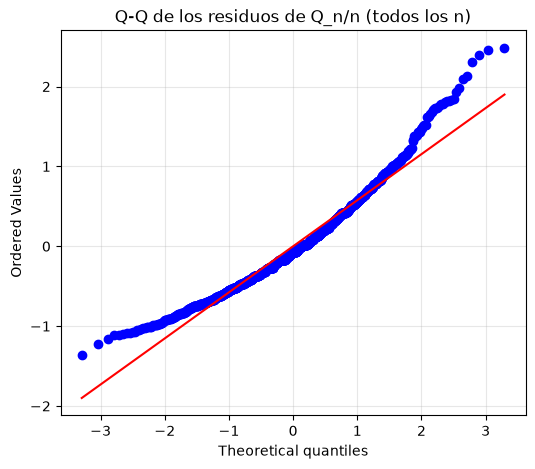

,W,p-valor,¿rechaza al 5 %?
n,,,
10,0.9073,0.0000,True
20,0.9113,0.0000,True
50,0.9425,0.0000,True
100,0.9504,0.0000,True
200,0.9529,0.0000,True
500,0.9657,0.0001,True
1000,0.9626,0.0000,True


In [22]:
# Shapiro-Wilk para todos los n juntos
res_q_todos = r_q_todos["resid"]
W_q, p_q = stats.shapiro(res_q_todos)
print(f"Shapiro-Wilk, residuos Quicksort (todos los n): W = {W_q:.4f}, p-valor = {p_q:.2e}")

# Gráfico Q-Q
fig, ax = plt.subplots(figsize=(6, 5))
stats.probplot(res_q_todos, dist="norm", plot=ax)
ax.set_title("Q-Q de los residuos de Q_n/n (todos los n)")
ax.grid(alpha=0.3)
plt.show()

# Shapiro-Wilk para cada n por separado
b0_hat_q, b1_hat_q = r_q_todos["beta"]
filas_q_d = []
for m in ns:
    res_m_q = (np.array(qn_tamanos[m]) / m) - (b0_hat_q + b1_hat_q * np.log(m))
    W_mq, p_mq = stats.shapiro(res_m_q)
    filas_q_d.append({"n": m, "W": W_mq, "p-valor": p_mq, "¿rechaza al 5 %?": p_mq < 0.05})

tabla_42d = pd.DataFrame(filas_q_d).set_index("n")
display(tabla_42d.round(4))

**Explicación 4.2 d):**
El test vuelve a rechazar la normalidad, pero **la causa del rechazo no es la misma que en insertion sort**. En insertion sort ($S_n$), la variable subyacente convergía a una distribución normal, pero el test fallaba localmente porque la variable cuenta eventos discretos acotados (el efecto era visible por una mala especificación de la varianza en la regresión). 

En el caso de Quicksort, $Q_n$ es intrínsecamente asimétrica. La distribución de la cantidad de comparaciones de Quicksort, tras ser normalizada, converge a una distribución límite particular (distribución de Quicksort) que es marcadamente asimétrica hacia la derecha, no a una distribución Normal. Por lo tanto, el supuesto de normalidad en los residuos no se cumple ni para la muestra combinada ni para los $n$ evaluados de forma separada.